In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# Install the necessary libraries
!pip install -q transformers datasets evaluate accelerate matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.0 MB/s eta 0:00:00a 0:00:01


In [3]:
import pandas as pd
import urllib.request
import tarfile
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import evaluate

# 1. Download and extract the raw dataset
url = "https://dl.fbaipublicfiles.com/parlai/empatheticdialogues/empatheticdialogues.tar.gz"
print("Downloading dataset...")
urllib.request.urlretrieve(url, "empatheticdialogues.tar.gz")

print("Extracting files...")
with tarfile.open("empatheticdialogues.tar.gz", "r:gz") as tar:
    tar.extractall()

# 2. Load the CSVs with pandas, explicitly telling it to skip any messy rows
print("Cleaning and loading data...")
df_train = pd.read_csv("empatheticdialogues/train.csv", on_bad_lines="skip")
df_valid = pd.read_csv("empatheticdialogues/valid.csv", on_bad_lines="skip")
df_test = pd.read_csv("empatheticdialogues/test.csv", on_bad_lines="skip")

# 3. Convert the clean pandas tables back into the Hugging Face dictionary format
dataset = DatasetDict({
    "train": Dataset.from_pandas(df_train),
    "validation": Dataset.from_pandas(df_valid),
    "test": Dataset.from_pandas(df_test)
})

# 4. View the first 5 rows!
print("Dataset loaded successfully!")
display_data = dataset['train'].to_pandas()
display(display_data.head(5))

Extracting files...


/tmp/ipykernel_55/2082806120.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Cleaning and loading data...
Dataset loaded successfully!


,conv_id,utterance_idx,context,prompt,speaker_idx,utterance,selfeval,tags
0,hit:0_conv:1,1,sentimental,I remember going to the fireworks with my best...,1,I remember going to see the fireworks with my ...,5|5|5_2|2|5,None
1,hit:0_conv:1,2,sentimental,I remember going to the fireworks with my best...,0,Was this a friend you were in love with_comma_...,5|5|5_2|2|5,None
2,hit:0_conv:1,3,sentimental,I remember going to the fireworks with my best...,1,This was a best friend. I miss her.,5|5|5_2|2|5,None
3,hit:0_conv:1,4,sentimental,I remember going to the fireworks with my best...,0,Where has she gone?,5|5|5_2|2|5,None
4,hit:0_conv:1,5,sentimental,I remember going to the fireworks with my best...,1,We no longer talk.,5|5|5_2|2|5,None


In [4]:
dataset.shape

{'train': (76668, 8), 'validation': (6318, 8), 'test': (5701, 8)}

In [5]:
display_data["context"].unique()

array(['sentimental', 'afraid', 'proud', 'faithful', 'terrified',
       'joyful', 'angry', 'sad', 'jealous', 'grateful', 'prepared',
       'embarrassed', 'excited', 'annoyed', 'lonely', 'ashamed', 'guilty',
       'surprised', 'nostalgic', 'confident', 'furious', 'disappointed',
       'caring', 'trusting', 'disgusted', 'anticipating', 'anxious',
       'hopeful', 'content', 'impressed', 'apprehensive', 'devastated'],
      dtype=object)

In [6]:
display_data["context"].value_counts()

context
surprised       3956
excited         2935
angry           2740
proud           2719
annoyed         2642
sad             2634
afraid          2510
lonely          2503
grateful        2487
terrified       2487
guilty          2463
anxious         2456
disgusted       2447
confident       2440
anticipating    2439
hopeful         2404
furious         2394
impressed       2381
disappointed    2356
nostalgic       2350
joyful          2346
jealous         2329
prepared        2292
content         2214
devastated      2192
embarrassed     2191
sentimental     2073
caring          2054
trusting        2001
ashamed         1976
apprehensive    1822
faithful        1435
Name: count, dtype: int64

In [7]:
# ==========================================
# PART 2: DEFINE THE 7 BUCKETS
# ==========================================
emotion_mapping = {
    "angry": "Anger", "furious": "Anger", "annoyed": "Anger", "disgusted": "Anger", "jealous": "Anger",
    "afraid": "Fear & Tension", "terrified": "Fear & Tension", "anxious": "Fear & Tension", "apprehensive": "Fear & Tension",
    "sad": "Sadness", "lonely": "Sadness", "devastated": "Sadness", "disappointed": "Sadness",
    "excited": "Joy & Confidence", "proud": "Joy & Confidence", "grateful": "Joy & Confidence", "joyful": "Joy & Confidence", "content": "Joy & Confidence", "impressed": "Joy & Confidence", "hopeful": "Joy & Confidence", "confident": "Joy & Confidence",
    "caring": "Connection & Trust", "trusting": "Connection & Trust", "faithful": "Connection & Trust",
    "guilty": "Vulnerability", "embarrassed": "Vulnerability", "ashamed": "Vulnerability",
    "nostalgic": "Suspense & Reflection", "sentimental": "Suspense & Reflection", "surprised": "Suspense & Reflection", "anticipating": "Suspense & Reflection", "prepared": "Suspense & Reflection"
}

grouped_labels = list(set(emotion_mapping.values()))
new_label2id = {label: i for i, label in enumerate(grouped_labels)}
new_id2label = {i: label for i, label in enumerate(grouped_labels)}

# ==========================================
# PART 3: UPGRADED GPT-2 TOKENIZATION 
# ==========================================
tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left" 

def group_and_tokenize(examples):
    # THE FIX: Combine the background situation ('prompt') with the spoken words ('utterance')
    combined_text = [
        f"Situation: {str(p).replace('_comma_', ',')} Dialogue: {str(u).replace('_comma_', ',')}" 
        for p, u in zip(examples['prompt'], examples['utterance'])
    ]
    
    # We increase max_length slightly to accommodate the extra context
    encoding = tokenizer(combined_text, padding="max_length", truncation=True, max_length=160)
    
    new_label_strings = [emotion_mapping[emotion] for emotion in examples['context']]
    encoding['label'] = [new_label2id[label] for label in new_label_strings]
    return encoding

print("Tokenizing combined context data for GPT-2...")
gpt_encoded_dataset = dataset.map(group_and_tokenize, batched=True)
print("Done! Ready for upgraded training.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/6318 [00:00<?, ? examples/s]

Map:   0%|          | 0/5701 [00:00<?, ? examples/s]

Done! Ready for upgraded training.


In [ ]:
# ==========================================
# PART 4: TRAIN THE UPGRADED GPT MODEL
# ==========================================
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments, EarlyStoppingCallback
import evaluate
import numpy as np

model = AutoModelForSequenceClassification.from_pretrained(
    "gpt2",
    num_labels=len(grouped_labels),
    id2label=new_id2label,
    label2id=new_label2id
)
model.config.pad_token_id = model.config.eos_token_id

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, true_labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=predictions, references=true_labels)

training_args = TrainingArguments(
    output_dir="./gpt2_context_vibe_model", 
    eval_strategy="epoch",         
    save_strategy="epoch",         
    learning_rate=5e-5,              # Slightly higher learning rate as suggested by research
    lr_scheduler_type="cosine",      
    warmup_ratio=0.1,                
    per_device_train_batch_size=16,  
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,   # THE FIX: Simulates a batch size of 32 for better learning stability!
    num_train_epochs=5,              
    weight_decay=0.01,               
    logging_steps=100,             
    load_best_model_at_end=True,     
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=2,              
    report_to="none"               
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=gpt_encoded_dataset["train"],
    eval_dataset=gpt_encoded_dataset["validation"],
    processing_class=tokenizer,     
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)] # THE FIX: Give the model more time to recover from bad epochs
)

print("Starting upgraded GPT-2 training with full context...")
trainer.train()

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Starting upgraded GPT-2 training with full context...


Epoch,Training Loss,Validation Loss,Accuracy
1,1.137788,0.780167,0.744698
2,0.461689,1.112508,0.744065
3,0.145454,1.576832,0.744539
4,0.060252,1.901922,0.745806


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

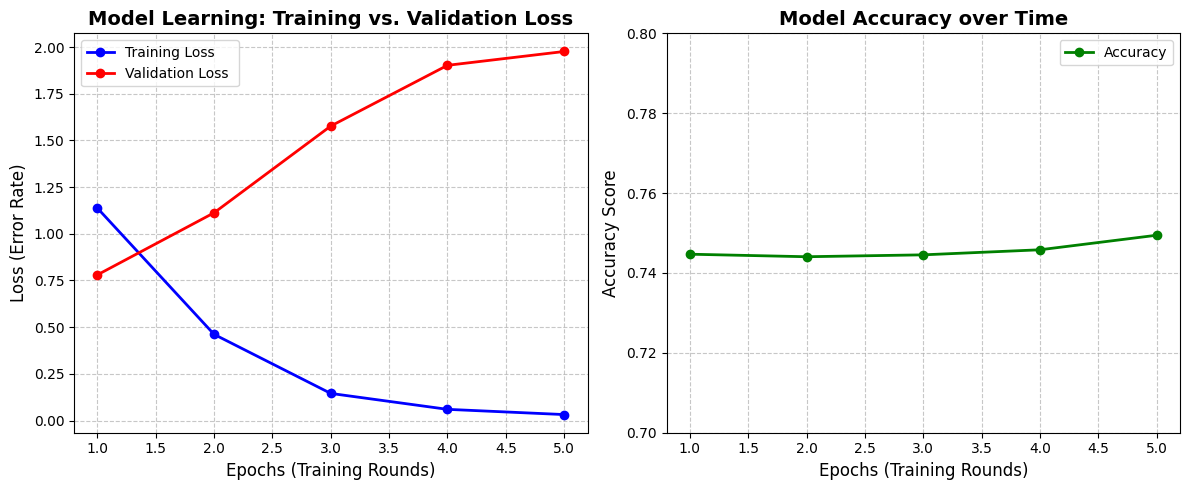

In [18]:
import matplotlib.pyplot as plt

# 1. The exact numbers from your training logs!
epochs = [1, 2, 3, 4, 5]
train_loss = [1.137788, 0.461689, 0.145454, 0.060252, 0.032247]
val_loss = [0.780167, 1.112508, 1.576832, 1.901922, 1.975995]
accuracy = [0.744698, 0.744065, 0.744539, 0.745806, 0.749446]

# 2. Set up a wide canvas for two side-by-side graphs
plt.figure(figsize=(12, 5))

# --- GRAPH 1: The Overfitting Proof (Loss) ---
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Training Loss ', marker='o', color='blue', linewidth=2)
plt.plot(epochs, val_loss, label='Validation Loss ', marker='o', color='red', linewidth=2)
plt.title('Model Learning: Training vs. Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epochs (Training Rounds)', fontsize=12)
plt.ylabel('Loss (Error Rate)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# --- GRAPH 2: The Accuracy Holding Steady ---
plt.subplot(1, 2, 2)
plt.plot(epochs, accuracy, label='Accuracy', marker='o', color='green', linewidth=2)
plt.title('Model Accuracy over Time', fontsize=14, fontweight='bold')
plt.xlabel('Epochs (Training Rounds)', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.ylim(0.70, 0.80) # Zoom in to see the 74% to 75% jump clearly
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# 3. Show the graphs
plt.tight_layout()
plt.show()

In [21]:
print("--- OFFICIAL MODEL VALIDATION TESTS ---\n")

# 1. A professional, diverse test suite covering all 7 core categories
official_test_cases = [
    {
        "expected_vibe": "Anger",
        "situation": "A customer is complaining about a broken product they just bought.",
        "dialogue": "I literally just took this out of the box and it is already shattered. I want a refund right now."
    },
    {
        "expected_vibe": "Fear & Tension",
        "situation": "Someone is trapped in a stalled elevator during a power outage.",
        "dialogue": "The lights just went out and the emergency button isn't working. We need to get out of here!"
    },
    {
        "expected_vibe": "Sadness",
        "situation": "A person is talking about losing their childhood pet.",
        "dialogue": "The house feels so empty without him running to the door every time I come home."
    },
    {
        "expected_vibe": "Joy & Confidence",
        "situation": "A student finding out they passed their final engineering project.",
        "dialogue": "I can't believe we actually got an A! All those sleepless nights coding finally paid off."
    },
    {
        "expected_vibe": "Connection & Trust",
        "situation": "Two friends talking after a long period apart.",
        "dialogue": "No matter how much time passes, I know I can always count on you to have my back."
    },
    {
        "expected_vibe": "Vulnerability",
        "situation": "Someone admitting they made a mistake at work.",
        "dialogue": "I messed up the presentation. I was so nervous that I completely forgot my talking points, and I feel terrible about it."
    },
    {
        "expected_vibe": "Suspense & Reflection",
        "situation": "A detective thinking about an unsolved case.",
        "dialogue": "Every piece of evidence points to him, but something just isn't adding up. I am missing something right in front of me."
    }
]

# 2. Run the tests and format the output cleanly for a report
for i, test in enumerate(official_test_cases):
    combined_quote = f"Situation: {test['situation']} Dialogue: {test['dialogue']}"
    result = emotion_classifier(combined_quote)
    
    print(f"Test {i+1}: Testing '{test['expected_vibe']}'")
    print(f"Input: {combined_quote}")
    print(f"Model Prediction: {result[0]['label']}")
    print(f"Confidence Score: {result[0]['score']:.4f}")
    
    # Check if the model got it right!
    if result[0]['label'] == test['expected_vibe']:
        print("Result: ✅ MATCH")
    else:
        print("Result: ❌ MISMATCH")
    print("-" * 60)

--- OFFICIAL MODEL VALIDATION TESTS ---

Test 1: Testing 'Anger'
Input: Situation: A customer is complaining about a broken product they just bought. Dialogue: I literally just took this out of the box and it is already shattered. I want a refund right now.
Model Prediction: Anger
Confidence Score: 0.9935
Result: ✅ MATCH
------------------------------------------------------------
Test 2: Testing 'Fear & Tension'
Input: Situation: Someone is trapped in a stalled elevator during a power outage. Dialogue: The lights just went out and the emergency button isn't working. We need to get out of here!
Model Prediction: Fear & Tension
Confidence Score: 0.9999
Result: ✅ MATCH
------------------------------------------------------------
Test 3: Testing 'Sadness'
Input: Situation: A person is talking about losing their childhood pet. Dialogue: The house feels so empty without him running to the door every time I come home.
Model Prediction: Suspense & Reflection
Confidence Score: 0.6034
Result: ❌

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Generating AI Brain Scans for Official Tests...



/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


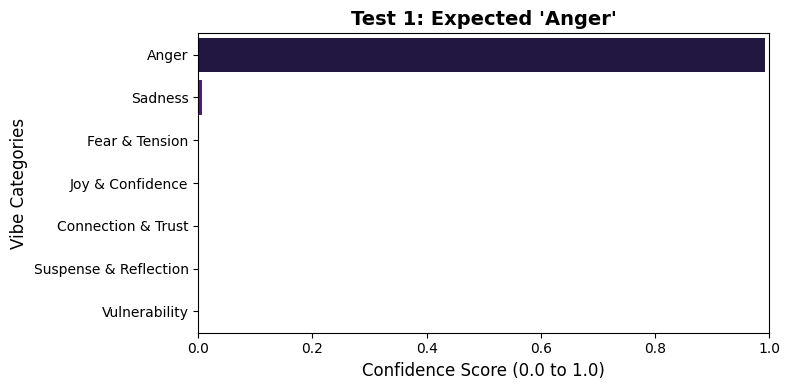

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


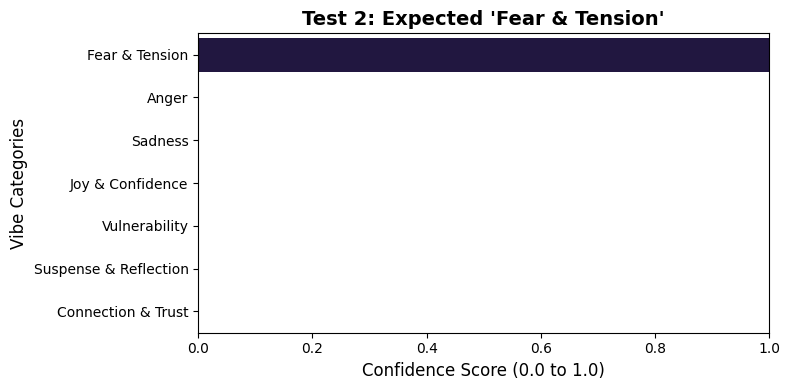

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


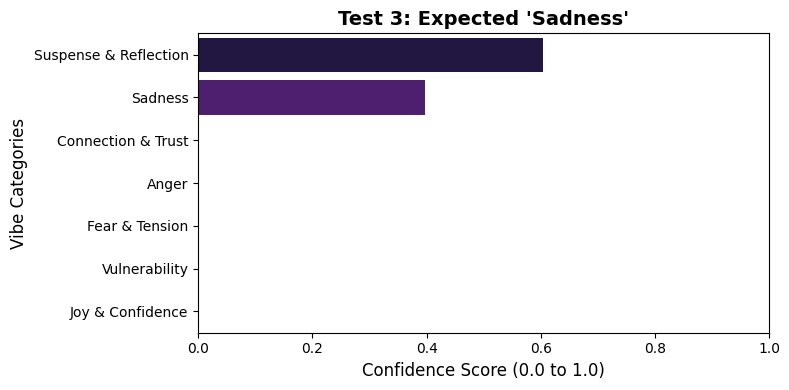

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


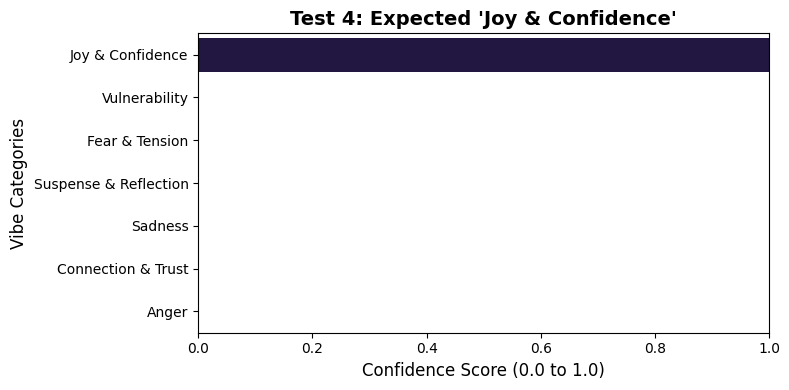

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


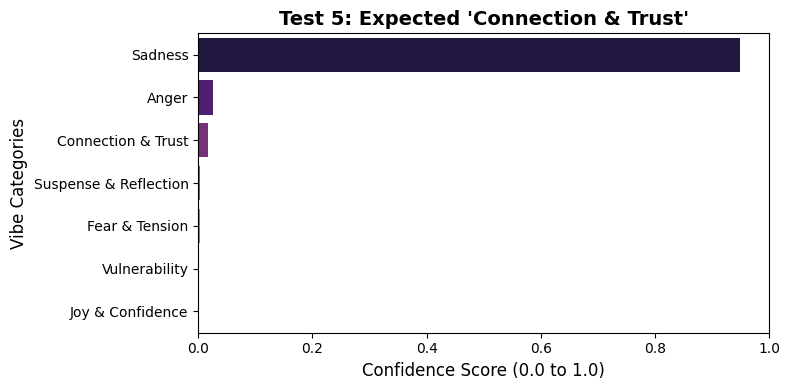

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


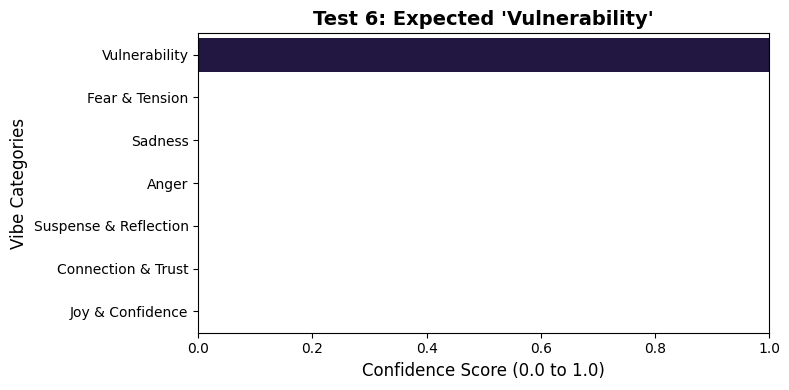

------------------------------------------------------------


/tmp/ipykernel_55/594884046.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='magma')


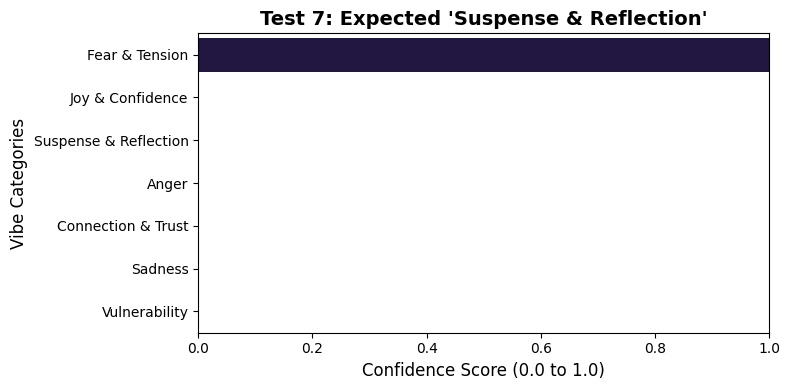

------------------------------------------------------------


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from transformers import pipeline

# 1. Update the pipeline to return ALL scores by adding top_k=None
emotion_classifier_all = pipeline(
    "text-classification", 
    model=best_checkpoint, 
    tokenizer=tokenizer,
    top_k=None 
)

# 2. Our official, non-romance testing suite
official_test_cases = [
    {
        "expected_vibe": "Anger",
        "situation": "A customer is complaining about a broken product they just bought.",
        "dialogue": "I literally just took this out of the box and it is already shattered. I want a refund right now."
    },
    {
        "expected_vibe": "Fear & Tension",
        "situation": "Someone is trapped in a stalled elevator during a power outage.",
        "dialogue": "The lights just went out and the emergency button isn't working. We need to get out of here!"
    },
    {
        "expected_vibe": "Sadness",
        "situation": "A person is talking about losing their childhood pet.",
        "dialogue": "The house feels so empty without him running to the door every time I come home."
    },
    {
        "expected_vibe": "Joy & Confidence",
        "situation": "A student finding out they passed their final engineering project.",
        "dialogue": "I can't believe we actually got an A! All those sleepless nights coding finally paid off."
    },
    {
        "expected_vibe": "Connection & Trust",
        "situation": "Two friends talking after a long period apart.",
        "dialogue": "No matter how much time passes, I know I can always count on you to have my back."
    },
    {
        "expected_vibe": "Vulnerability",
        "situation": "Someone admitting they made a mistake at work.",
        "dialogue": "I messed up the presentation. I was so nervous that I completely forgot my talking points, and I feel terrible about it."
    },
    {
        "expected_vibe": "Suspense & Reflection",
        "situation": "A detective thinking about an unsolved case.",
        "dialogue": "Every piece of evidence points to him, but something just isn't adding up. I am missing something right in front of me."
    }
]

print("Generating AI Brain Scans for Official Tests...\n")

# 3. Loop through each test and draw its own specific chart
for i, test in enumerate(official_test_cases):
    combined_quote = f"Situation: {test['situation']} Dialogue: {test['dialogue']}"
    
    # Get the predictions for all 7 buckets
    results = emotion_classifier_all(combined_quote)
    
    # Convert to a clean table and sort highest to lowest
    df = pd.DataFrame(results[0])
    df = df.sort_values(by='score', ascending=False)
    
    # Draw the Bar Chart
    plt.figure(figsize=(8, 4))
    sns.barplot(x='score', y='label', data=df, palette='magma')
    
    # Titles and Labels
    plt.title(f"Test {i+1}: Expected '{test['expected_vibe']}'", fontsize=14, fontweight='bold')
    plt.xlabel('Confidence Score (0.0 to 1.0)', fontsize=12)
    plt.ylabel('Vibe Categories', fontsize=12)
    plt.xlim(0, 1) # Lock the bottom axis
    
    # Show the graph
    plt.tight_layout()
    plt.show()
    print("-" * 60)